In [51]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


In [52]:
test = '/home/niekschlooz/Downloads/lab2_test.csv'
train = '/home/niekschlooz/Downloads/lab2_train.csv'
trainset = pd.read_csv(train)
testset = pd.read_csv(test)

trainset.info()

<class 'pandas.DataFrame'>
RangeIndex: 8761 entries, 0 to 8760
Data columns (total 45 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   DATETIME  8761 non-null   str    
 1   L_T1      8761 non-null   float64
 2   L_T2      8761 non-null   float64
 3   L_T3      8761 non-null   float64
 4   L_T4      8761 non-null   float64
 5   L_T5      8761 non-null   float64
 6   L_T6      8761 non-null   float64
 7   L_T7      8761 non-null   float64
 8   F_PU1     8761 non-null   float64
 9   S_PU1     8761 non-null   int64  
 10  F_PU2     8761 non-null   float64
 11  S_PU2     8761 non-null   int64  
 12  F_PU3     8761 non-null   int64  
 13  S_PU3     8761 non-null   int64  
 14  F_PU4     8761 non-null   float64
 15  S_PU4     8761 non-null   int64  
 16  F_PU5     8761 non-null   int64  
 17  S_PU5     8761 non-null   int64  
 18  F_PU6     8761 non-null   float64
 19  S_PU6     8761 non-null   int64  
 20  F_PU7     8761 non-null   float64
 21  S_

In [53]:
testset.info()

<class 'pandas.DataFrame'>
RangeIndex: 4177 entries, 0 to 4176
Data columns (total 45 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   DATETIME  4177 non-null   str    
 1   L_T1      4177 non-null   float64
 2   L_T2      4177 non-null   float64
 3   L_T3      4177 non-null   float64
 4   L_T4      4177 non-null   float64
 5   L_T5      4177 non-null   float64
 6   L_T6      4177 non-null   float64
 7   L_T7      4177 non-null   float64
 8   F_PU1     4177 non-null   float64
 9   S_PU1     4177 non-null   int64  
 10  F_PU2     4177 non-null   float64
 11  S_PU2     4177 non-null   int64  
 12  F_PU3     4177 non-null   int64  
 13  S_PU3     4177 non-null   int64  
 14  F_PU4     4177 non-null   float64
 15  S_PU4     4177 non-null   int64  
 16  F_PU5     4177 non-null   int64  
 17  S_PU5     4177 non-null   int64  
 18  F_PU6     4177 non-null   float64
 19  S_PU6     4177 non-null   int64  
 20  F_PU7     4177 non-null   float64
 21  S_

              L_T1      L_T2      L_T3      L_T4      L_T5      L_T6  \
L_T1      1.000000 -0.241856 -0.051060 -0.013560 -0.106825 -0.088293   
L_T2     -0.241856  1.000000 -0.239759  0.042281 -0.118911 -0.163622   
L_T3     -0.051060 -0.239759  1.000000  0.221428  0.070027 -0.067903   
L_T4     -0.013560  0.042281  0.221428  1.000000 -0.030064 -0.094458   
L_T5     -0.106825 -0.118911  0.070027 -0.030064  1.000000  0.051074   
L_T6     -0.088293 -0.163622 -0.067903 -0.094458  0.051074  1.000000   
L_T7      0.010477  0.036533  0.239311  0.150012 -0.043320  0.472008   
F_PU1     0.038016 -0.402876 -0.099840 -0.005100 -0.039171  0.070081   
S_PU1          NaN       NaN       NaN       NaN       NaN       NaN   
F_PU2    -0.259267  0.409448  0.088429  0.003766  0.049731 -0.009500   
S_PU2    -0.231163  0.410286  0.091363  0.003196  0.047470 -0.019742   
F_PU3          NaN       NaN       NaN       NaN       NaN       NaN   
S_PU3          NaN       NaN       NaN       NaN       NaN      

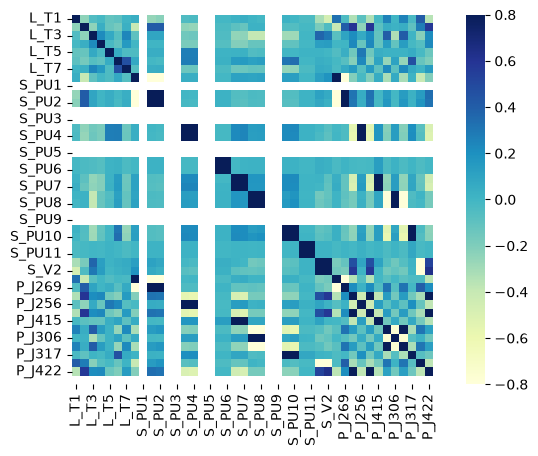

              L_T1      L_T2      L_T3      L_T4      L_T5      L_T6  \
L_T1      1.000000 -0.250684 -0.046836  0.008463 -0.106485 -0.053738   
L_T2     -0.250684  1.000000 -0.231006  0.066508 -0.099861 -0.163370   
L_T3     -0.046836 -0.231006  1.000000  0.197330  0.054912 -0.079414   
L_T4      0.008463  0.066508  0.197330  1.000000 -0.033190 -0.081583   
L_T5     -0.106485 -0.099861  0.054912 -0.033190  1.000000  0.107738   
L_T6     -0.053738 -0.163370 -0.079414 -0.081583  0.107738  1.000000   
L_T7      0.055432  0.000885  0.245431  0.132570 -0.017983  0.489866   
F_PU1     0.007194 -0.392417 -0.078215 -0.065142 -0.036421  0.048450   
S_PU1          NaN       NaN       NaN       NaN       NaN       NaN   
F_PU2    -0.233661  0.410211  0.072222  0.054495  0.046216 -0.002425   
S_PU2    -0.204146  0.409832  0.073211  0.054399  0.044608 -0.010020   
F_PU3          NaN       NaN       NaN       NaN       NaN       NaN   
S_PU3          NaN       NaN       NaN       NaN       NaN      

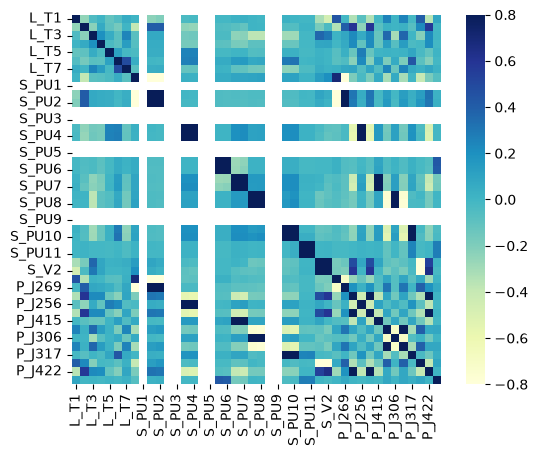

In [54]:
co_mtx = trainset.corr(numeric_only=True)

# Print correlation matrix
print(co_mtx)

# Plot correlation heatmap
sns.heatmap(co_mtx,           # Verbergt de vakjes die te veel op 'normaal' lijken
            vmax=.8, 
            vmin=-.8,
            square=True, 
            cmap='YlGnBu', 
            annot=False,         # Laat de getallen zien (van de FRAUDE matrix)
            fmt=".2f")

# Display heatmap
plt.show()


co_mtx = testset.corr(numeric_only=True)

# Print correlation matrix
print(co_mtx)

# Plot correlation heatmap
sns.heatmap(co_mtx,           # Verbergt de vakjes die te veel op 'normaal' lijken
            vmax=.8, 
            vmin=-.8,
            square=True, 
            cmap='YlGnBu', 
            annot=False,         # Laat de getallen zien (van de FRAUDE matrix)
            fmt=".2f")

# Display heatmap
plt.show()

In [55]:
trainset = trainset.drop(['S_PU1','S_PU3','S_PU5','S_PU9', 'F_PU9','F_PU3', 'F_PU5', 'ATT_FLAG','DATETIME'], axis=1)
testset = testset.drop(['S_PU1','S_PU3','S_PU5','S_PU9', 'F_PU9','F_PU3', 'F_PU5', 'ATT_FLAG', 'DATETIME'], axis=1)

In [56]:
testset.info()

<class 'pandas.DataFrame'>
RangeIndex: 4177 entries, 0 to 4176
Data columns (total 36 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   L_T1    4177 non-null   float64
 1   L_T2    4177 non-null   float64
 2   L_T3    4177 non-null   float64
 3   L_T4    4177 non-null   float64
 4   L_T5    4177 non-null   float64
 5   L_T6    4177 non-null   float64
 6   L_T7    4177 non-null   float64
 7   F_PU1   4177 non-null   float64
 8   F_PU2   4177 non-null   float64
 9   S_PU2   4177 non-null   int64  
 10  F_PU4   4177 non-null   float64
 11  S_PU4   4177 non-null   int64  
 12  F_PU6   4177 non-null   float64
 13  S_PU6   4177 non-null   int64  
 14  F_PU7   4177 non-null   float64
 15  S_PU7   4177 non-null   int64  
 16  F_PU8   4177 non-null   float64
 17  S_PU8   4177 non-null   int64  
 18  F_PU10  4177 non-null   float64
 19  S_PU10  4177 non-null   int64  
 20  F_PU11  4177 non-null   float64
 21  S_PU11  4177 non-null   int64  
 22  F_V2    417

            L_T1      L_T2      L_T3      L_T4      L_T5      L_T6      L_T7  \
L_T1    1.000000 -0.241856 -0.051060 -0.013560 -0.106825 -0.088293  0.010477   
L_T2   -0.241856  1.000000 -0.239759  0.042281 -0.118911 -0.163622  0.036533   
L_T3   -0.051060 -0.239759  1.000000  0.221428  0.070027 -0.067903  0.239311   
L_T4   -0.013560  0.042281  0.221428  1.000000 -0.030064 -0.094458  0.150012   
L_T5   -0.106825 -0.118911  0.070027 -0.030064  1.000000  0.051074 -0.043320   
L_T6   -0.088293 -0.163622 -0.067903 -0.094458  0.051074  1.000000  0.472008   
L_T7    0.010477  0.036533  0.239311  0.150012 -0.043320  0.472008  1.000000   
F_PU1   0.038016 -0.402876 -0.099840 -0.005100 -0.039171  0.070081 -0.068524   
F_PU2  -0.259267  0.409448  0.088429  0.003766  0.049731 -0.009500  0.041302   
S_PU2  -0.231163  0.410286  0.091363  0.003196  0.047470 -0.019742  0.045103   
F_PU4  -0.045289 -0.238824 -0.155974 -0.185903  0.269465  0.276224 -0.139141   
S_PU4  -0.031689 -0.260617 -0.141550 -0.

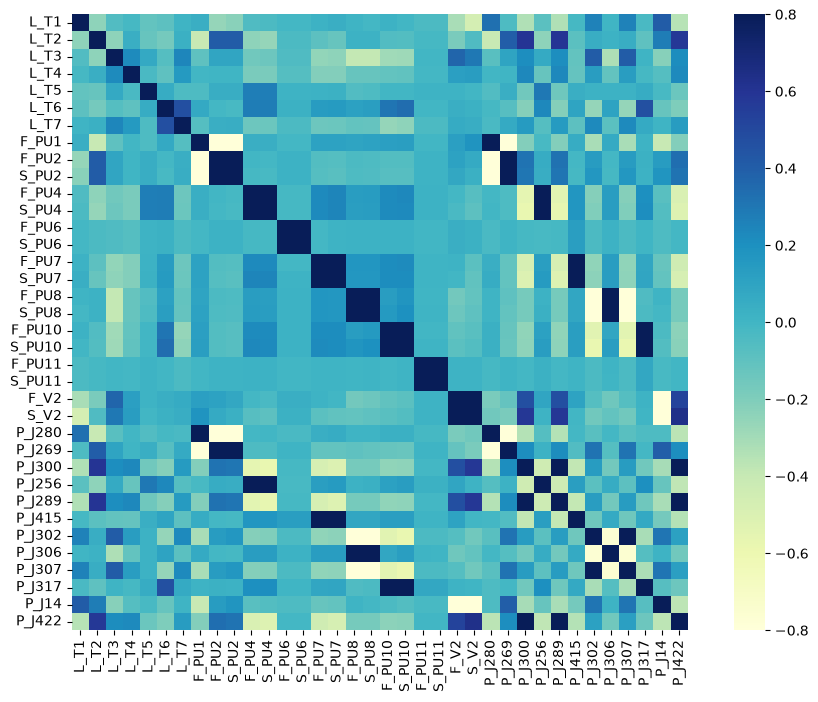

            L_T1      L_T2      L_T3      L_T4      L_T5      L_T6      L_T7  \
L_T1    1.000000 -0.250684 -0.046836  0.008463 -0.106485 -0.053738  0.055432   
L_T2   -0.250684  1.000000 -0.231006  0.066508 -0.099861 -0.163370  0.000885   
L_T3   -0.046836 -0.231006  1.000000  0.197330  0.054912 -0.079414  0.245431   
L_T4    0.008463  0.066508  0.197330  1.000000 -0.033190 -0.081583  0.132570   
L_T5   -0.106485 -0.099861  0.054912 -0.033190  1.000000  0.107738 -0.017983   
L_T6   -0.053738 -0.163370 -0.079414 -0.081583  0.107738  1.000000  0.489866   
L_T7    0.055432  0.000885  0.245431  0.132570 -0.017983  0.489866  1.000000   
F_PU1   0.007194 -0.392417 -0.078215 -0.065142 -0.036421  0.048450 -0.078452   
F_PU2  -0.233661  0.410211  0.072222  0.054495  0.046216 -0.002425  0.041655   
S_PU2  -0.204146  0.409832  0.073211  0.054399  0.044608 -0.010020  0.046745   
F_PU4  -0.036709 -0.241508 -0.157865 -0.170804  0.255347  0.267064 -0.114335   
S_PU4  -0.023748 -0.262219 -0.143805 -0.

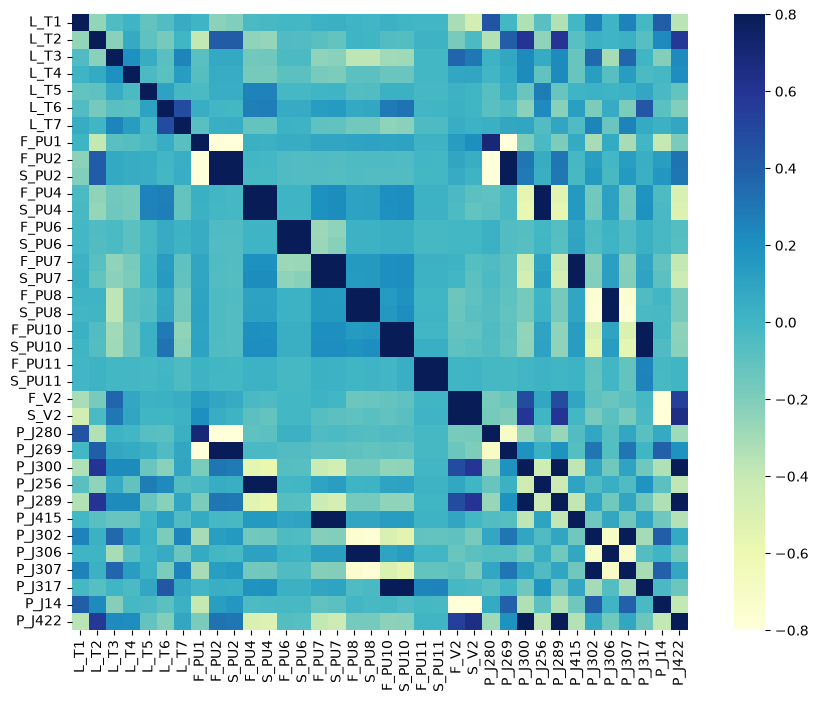

In [57]:
co_mtx = trainset.corr(numeric_only=True)

# Print correlation matrix
print(co_mtx)

plt.figure(figsize=(12, 8))

# Plot correlation heatmap
sns.heatmap(co_mtx,           # Verbergt de vakjes die te veel op 'normaal' lijken
            vmax=.8, 
            vmin=-.8,
            square=True, 
            cmap='YlGnBu', 
            annot=False,        
            fmt=".2f")

# Display heatmap
plt.show()


co_mtx = testset.corr(numeric_only=True)

# Print correlation matrix
print(co_mtx)

plt.figure(figsize=(12, 8))

# Plot correlation heatmap
sns.heatmap(co_mtx,           # Verbergt de vakjes die te veel op 'normaal' lijken
            vmax=.8, 
            vmin=-.8,
            square=True, 
            cmap='YlGnBu', 
            annot=False,         # Laat de getallen zien (van de FRAUDE matrix)
            fmt=".2f")

# Display heatmap
plt.show()

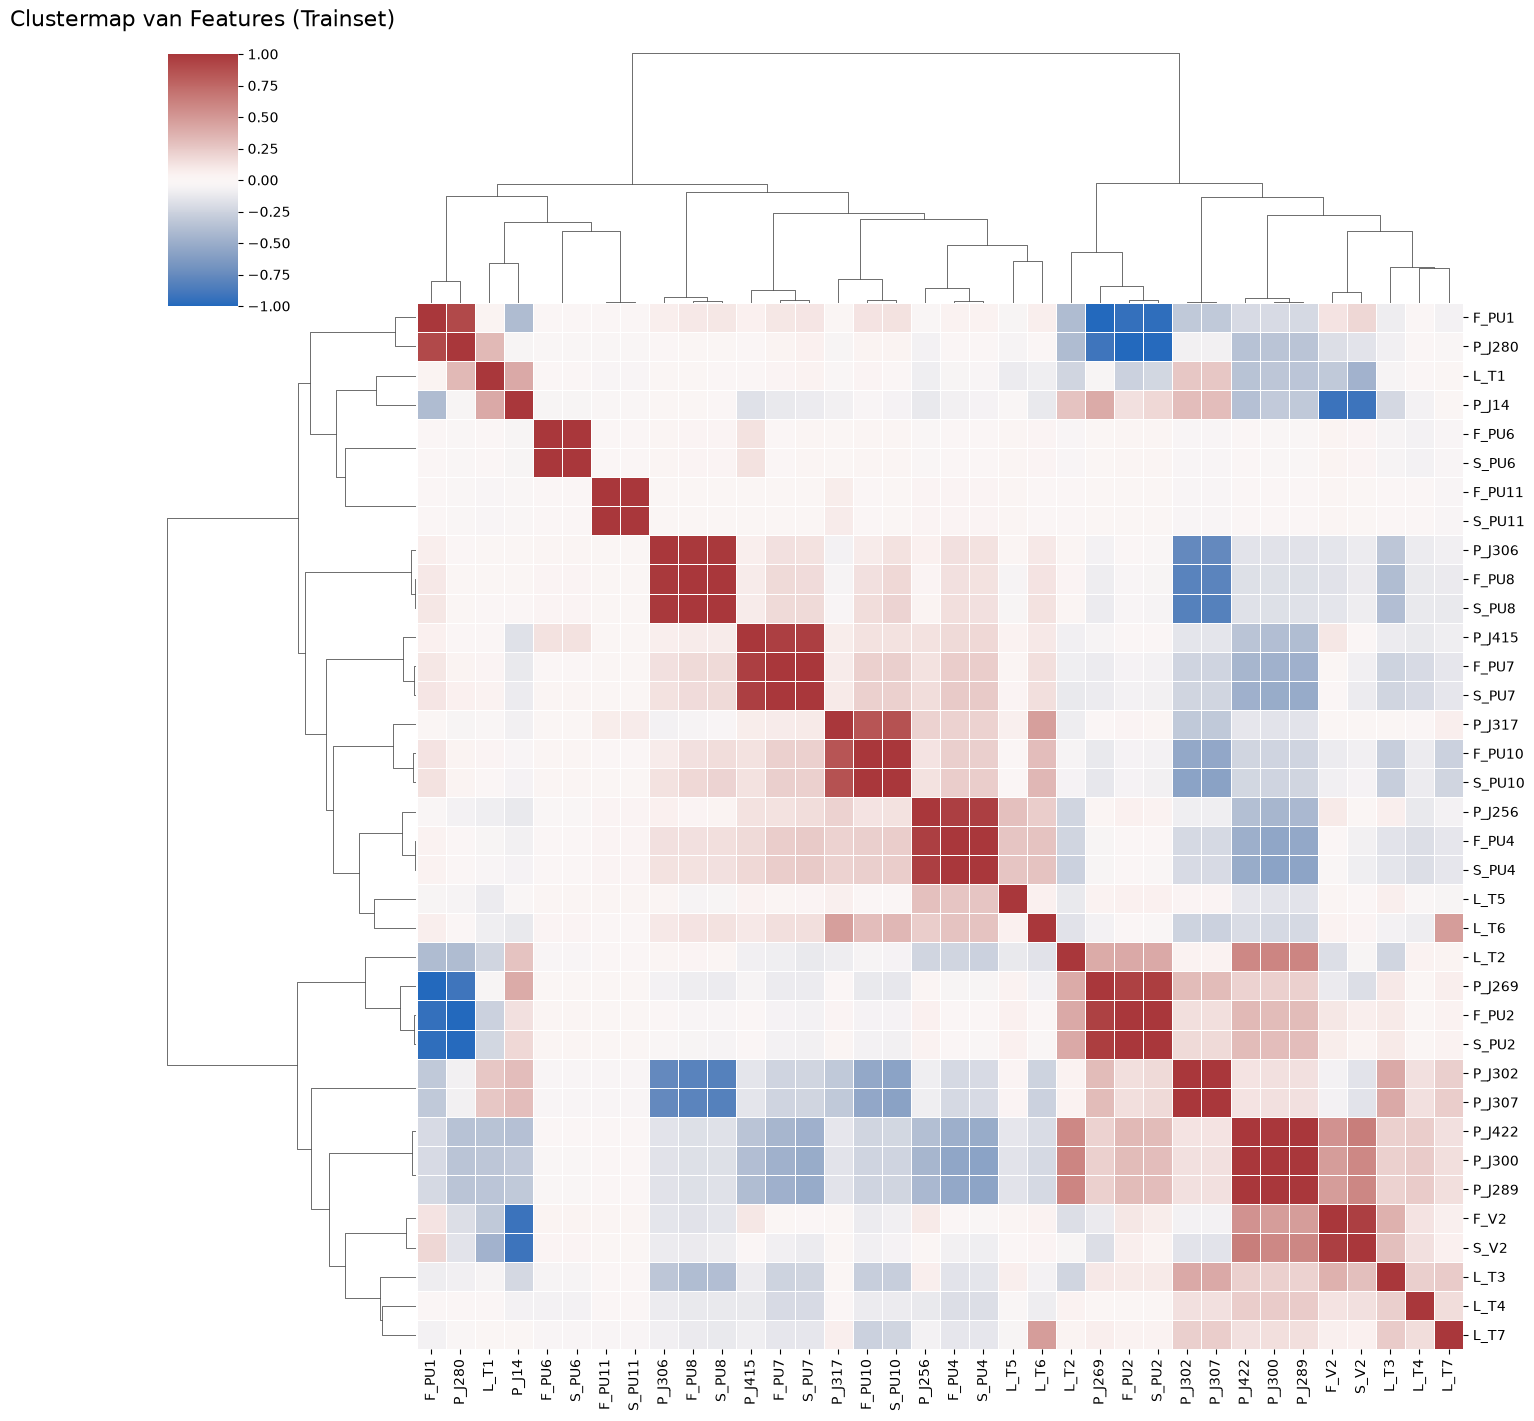

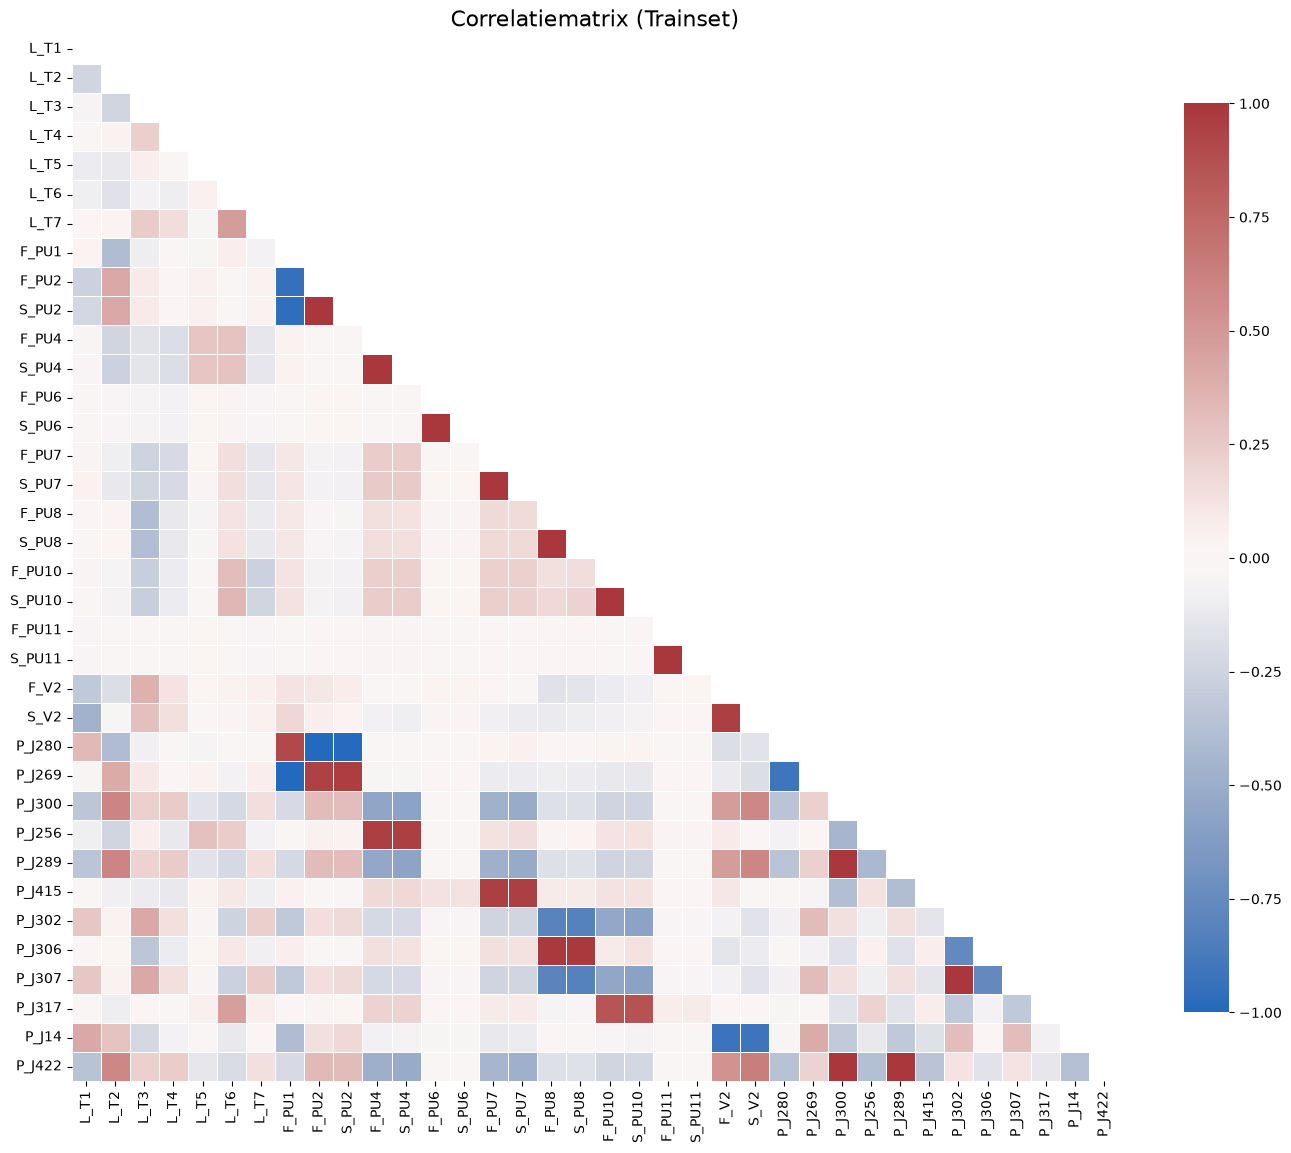

In [58]:
x_train = trainset
corr = x_train.corr()

# ==========================================
# VISUALISATIE 1: De Clustermap (Aanrader voor unsupervised!)
# ==========================================
# Groepeert variabelen met vergelijkbaar gedrag in blokken
sns.clustermap(corr, 
               cmap='vlag',          # Blauw/rood kleurenschaal
               vmin=-1.0, vmax=1.0,  # Schaal van -1 tot 1
               center=0,
               figsize=(14, 14),
               linewidths=0.5,
               method='ward')

plt.title('Clustermap van Features (Trainset)', fontsize=16, pad=20)
plt.show()

# ==========================================
# VISUALISATIE 2: De Triangle Mask Heatmap
# ==========================================
# Rustig overzicht zonder dubbele waardes
plt.figure(figsize=(14, 12))
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(corr, 
            mask=mask, 
            cmap='vlag', 
            vmin=-1.0, vmax=1.0, 
            center=0,
            square=True, 
            linewidths=0.5, 
            cbar_kws={"shrink": .8})

plt.title('Correlatiematrix (Trainset)', fontsize=16)
plt.tight_layout()
plt.show()

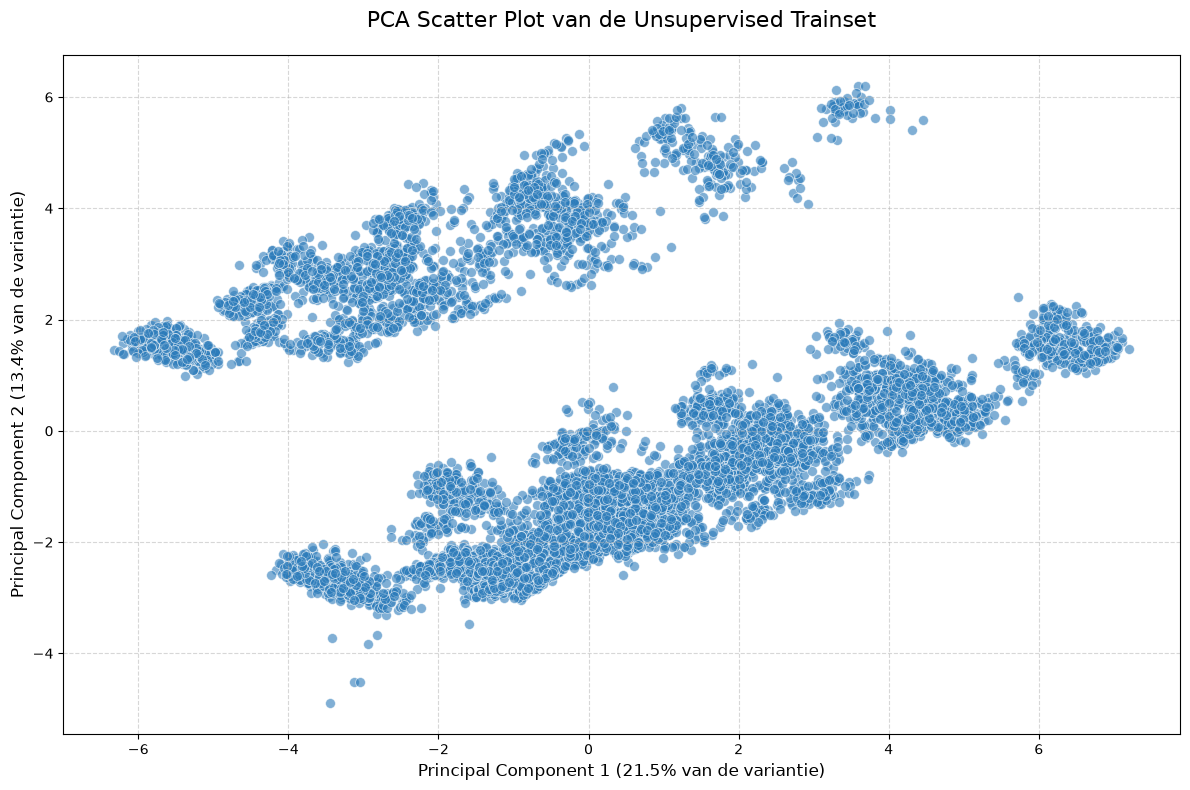

In [60]:
df_numeric = x_train.select_dtypes(include=[np.number])

# Eventuele lege waardes (NaN) opvullen met 0, anders loopt PCA vast
df_numeric = df_numeric.fillna(0)

# 3. Data Standaardiseren (Cruciaal voor PCA!)
# Dit zorgt ervoor dat elke variabele even zwaar weegt, 
# ongeacht of de getallen heel groot of heel klein zijn.
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df_numeric)

# 4. Voer PCA uit (we reduceren alles naar 2 componenten/assen voor een 2D plot)
pca = PCA(n_components=2)
pca_result = pca.fit_transform(scaled_data)

# Zet de resultaten in een handig nieuw DataFrame
pca_df = pd.DataFrame(data=pca_result, columns=['Principal Component 1', 'Principal Component 2'])

# 5. Visualiseer de resultaten in een Scatter Plot
plt.figure(figsize=(12, 8))

# We gebruiken alpha=0.6 zodat je goed kunt zien waar veel puntjes overlappen
sns.scatterplot(
    x='Principal Component 1', 
    y='Principal Component 2', 
    data=pca_df, 
    alpha=0.6,
    color='#2b7bba', # Een mooie, rustige kleur blauw
    s=50 # Grootte van de puntjes
)

# Voeg de percentages toe aan de assen (hoeveel van de variatie in je data ze weerspiegelen)
var_1 = pca.explained_variance_ratio_[0] * 100
var_2 = pca.explained_variance_ratio_[1] * 100

plt.title('PCA Scatter Plot van de Unsupervised Trainset', fontsize=16, pad=20)
plt.xlabel(f'Principal Component 1 ({var_1:.1f}% van de variantie)', fontsize=12)
plt.ylabel(f'Principal Component 2 ({var_2:.1f}% van de variantie)', fontsize=12)

# Voeg een raster toe voor de leesbaarheid
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()

In [ ]:

# import matplotlib.pyplot as plt
# import pandas as pd


# def plot_column_slice(
# df, column_name, start=0, end=500, figsize=(18, 4), color="#1f77b4"
# ):
#     # 1. Initialize the plot
#     fig, ax = plt.subplots(figsize=figsize)

#     # 2. Slice and ensure numeric type
#     sliced_series = pd.to_numeric(
#     df[column_name].iloc[start:end], errors="coerce"
#     )

#     # 3. Plot the feature
#     sliced_series.plot(ax=ax, color=color, linewidth=1.5)

#     # 4. Dynamic styling based on inputs
#     ax.set_title(
#     f"Feature: {column_name} (Rows {start} to {end})",
#     fontsize=14,
#     fontweight="bold",
#     pad=12,
#     )
#     ax.set_xlabel("Index / Time", fontsize=11)
#     ax.set_ylabel("Value", fontsize=11)
#     ax.grid(True, linestyle="--", alpha=0.6)

#     # 5. Prevent edge cut-offs and render
#     plt.tight_layout()
#     plt.show()


# for col in x_train.columns:
#     plot_column_slice(x_train, col, start=0, end=500)
print(testset.columns)

Index(['L_T1', 'L_T2', 'L_T3', 'L_T4', 'L_T5', 'L_T6', 'L_T7', 'F_PU1',
       'F_PU2', 'S_PU2', 'F_PU4', 'S_PU4', 'F_PU6', 'S_PU6', 'F_PU7', 'S_PU7',
       'F_PU8', 'S_PU8', 'F_PU10', 'S_PU10', 'F_PU11', 'S_PU11', 'F_V2',
       'S_V2', 'P_J280', 'P_J269', 'P_J300', 'P_J256', 'P_J289', 'P_J415',
       'P_J302', 'P_J306', 'P_J307', 'P_J317', 'P_J14', 'P_J422'],
      dtype='str')


/home/niekschlooz/Downloads/.venv/lib64/python3.14/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


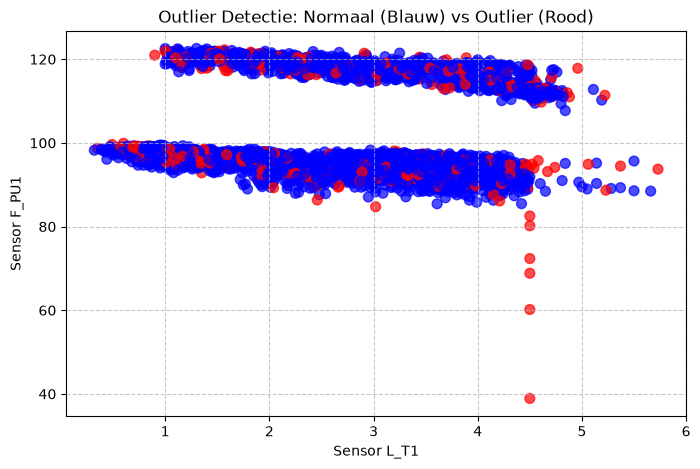

In [ ]:
from sklearn.neighbors import LocalOutlierFactor


clf = LocalOutlierFactor(n_neighbors=3, novelty=True)

# Train het model op de geschaalde 'normale' data
clf.fit(trainset)

# --- STAP 4: Resultaten bekijken ---
# Bereken de voorspellingen (1 = normaal, -1 = outlier)

voorspellingen = clf.predict(testset)
testset['Resultaat'] = voorspellingen

# --- 4. GRAFIEK MAKEN (Nieuw!) ---
# We bepalen de kleuren: 1 (normaal) wordt blauw, -1 (outlier) wordt rood
kleuren = testset['Resultaat'].map({1: 'blue', -1: 'red'})

# Maak het canvas (8 inch breed, 5 inch hoog)
kleuren = testset['Resultaat'].map({1: 'blue', -1: 'red'})

plt.figure(figsize=(8, 5))

# HIER ZIT DE OPLOSSING: We gebruiken nu jouw echte kolommen
plt.scatter(testset['L_T1'], testset['F_PU1'], c=kleuren, s=50, alpha=0.7)

# Pas de titels van de assen ook aan naar wat logisch is
plt.title('Outlier Detectie: Normaal (Blauw) vs Outlier (Rood)')
plt.xlabel('Sensor L_T1')
plt.ylabel('Sensor F_PU1')

plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

NameError: name 'scatter' is not defined

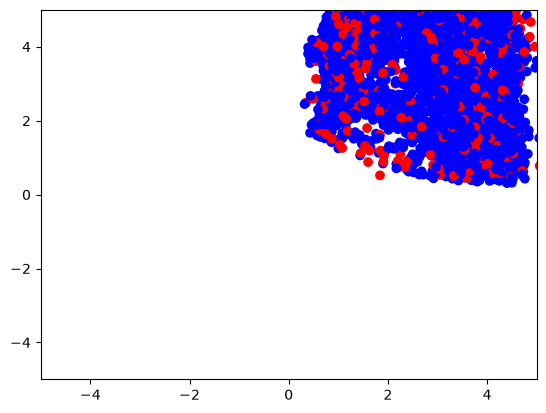

In [64]:
clf = LocalOutlierFactor(n_neighbors=20, contamination=0.1)
y_pred = clf.fit_predict(x_train)
# n_errors = (y_pred != ground_truth).sum()
X_scores = clf.negative_outlier_factor_

import matplotlib.pyplot as plt
from matplotlib.legend_handler import HandlerPathCollection


def update_legend_marker_size(handle, orig):
    "Customize size of the legend marker"
    handle.update_from(orig)
    handle.set_sizes([20])


plt.scatter(testset.iloc[:, 0], testset.iloc[:, 1], c=kleuren)
# plot circles with radius proportional to the outlier scores
radius = (X_scores.max() - X_scores) / (X_scores.max() - X_scores.min())
# scatter = plt.scatter(
#     x_train[:, 0],
#     x_train[:, 1],
#     s=1000 * radius,
#     edgecolors="r",
#     facecolors="none",
#     label="Outlier scores",
# )
plt.axis("tight")
plt.xlim((-5, 5))
plt.ylim((-5, 5))
# plt.xlabel("prediction errors: %d" % (n_errors))
plt.legend(
    handler_map={scatter: HandlerPathCollection(update_func=update_legend_marker_size)}
)
plt.title("Local Outlier Factor (LOF)")
plt.show()